# Task 3: Data Visualization - Retail Sales Story
**Goal:** transform raw data into charts and a dashboard, design them to reveal insights clearly, and tell a story that supports a decision.

**Business question:** *Where is the business making money, and where is it leaking it?*

| Task requirement | Where it is covered |
|---|---|
| Transform raw data into charts, graphs, dashboards | Sections 2-4 |
| Use Matplotlib / Seaborn (Tableau as extension) | All code cells; Tableau steps in `TABLEAU_GUIDE.md` |
| Design visuals that reveal insights clearly | Design rules in Section 3, one finding per chart |
| Craft a data story that supports decisions | Section 5 |
| Build a portfolio | Exported PNGs in `visuals/`, README, PDF report |


## 1. Load and understand the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

df = pd.read_csv("../data/retail_sales.csv", parse_dates=["order_date"])
print(df.shape)
df.head()

(3683, 9)


,order_id,order_date,region,segment,category,quantity,discount,sales,profit
0,ORD-103137,2023-01-01,Central,Home Office,Office Supplies,7,0.2,692.12,26.65
1,ORD-101459,2023-01-01,Central,Home Office,Office Supplies,4,0.1,107.47,9.29
2,ORD-102288,2023-01-01,East,Home Office,Office Supplies,2,0.0,71.34,12.21
3,ORD-101424,2023-01-02,Central,Home Office,Furniture,4,0.3,856.36,-19.39
4,ORD-100910,2023-01-02,West,Home Office,Technology,6,0.1,2226.52,315.61


**Data dictionary**

| Column | Meaning |
|---|---|
| order_id | Unique order |
| order_date | Date of order |
| region | West / East / Central / South |
| segment | Consumer / Corporate / Home Office |
| category | Technology / Furniture / Office Supplies |
| quantity | Units in the order |
| discount | Discount given (0 to 0.4) |
| sales | Revenue after discount |
| profit | Profit (can be negative) |


In [2]:
# Data quality checks
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "none")
print("Duplicate orders:", df.order_id.duplicated().sum())
print("Date range:", df.order_date.min().date(), "to", df.order_date.max().date())
df.describe().round(2)

Missing values:
 none
Duplicate orders: 0
Date range: 2023-01-01 to 2025-12-30


,order_date,quantity,discount,sales,profit
count,3683,3683.00,3683.00,3683.00,3683.00
mean,2024-07-22 08:44:42.161281,3.96,0.12,891.95,103.68
min,2023-01-01 00:00:00,1.00,0.00,12.76,-607.86
25%,2023-11-07 00:00:00,2.00,0.00,179.14,6.24
50%,2024-07-30 00:00:00,4.00,0.05,391.26,30.89
75%,2025-04-14 00:00:00,6.00,0.20,1185.34,104.57
max,2025-12-30 00:00:00,7.00,0.40,11297.49,2649.61
std,NaN,1.99,0.13,1151.40,231.14


## 2. Prepare features for analysis

In [3]:
df["year"] = df.order_date.dt.year
df["month"] = df.order_date.dt.month
df["ym"] = df.order_date.dt.to_period("M").dt.to_timestamp()
df["margin"] = df.profit / df.sales

total_sales, total_profit = df.sales.sum(), df.profit.sum()
print(f"Revenue ${total_sales:,.0f} | Profit ${total_profit:,.0f} | Margin {total_profit/total_sales:.1%}")

Revenue $3,285,042 | Profit $381,869 | Margin 11.6%


## 3. Design system for the visuals
Rules used for every chart:
1. **Title states the finding**, not just the topic.
2. **One color per category, used consistently** (blue, orange, green: a colorblind-safe trio).
3. **Sequential scale (one hue)** for magnitude, **diverging scale (blue/red around 0)** for profit.
4. **No dual axes**, light gridlines, direct labels instead of heavy legends.

In [4]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
CAT = {"Technology": BLUE, "Furniture": ORANGE, "Office Supplies": AQUA}
INK, INK2, MUTED, GRID, SURFACE, MID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb", "#f0efec"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#b52a2a", "#ee8a89", MID, "#6da7ec", "#184f95"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "axes.titlesize": 14,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 14,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False, "figure.dpi": 100})

def money(x, _=None):
    return f"${x/1e6:.1f}M" if abs(x) >= 1e6 else (f"${x/1e3:.0f}K" if abs(x) >= 1e3 else f"${x:.0f}")

### 3.1 Trend over time (line chart)
**Question:** is the business growing, and is there seasonality?

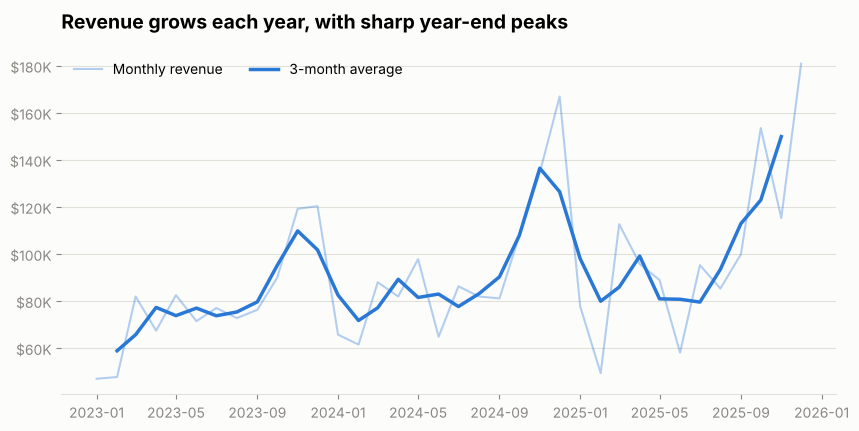

In [5]:
monthly = df.groupby("ym").sales.sum()
roll = monthly.rolling(3, center=True).mean()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly.index, monthly.values, color=BLUE, alpha=.35, lw=1.5, label="Monthly revenue")
ax.plot(roll.index, roll.values, color=BLUE, lw=2.5, label="3-month average")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money)); ax.grid(axis="x", visible=False)
ax.set_title("Revenue grows each year, with sharp year-end peaks"); ax.legend(loc="upper left", ncol=2)
plt.show()

**Insight:** revenue rose from about $954K (2023) to $1.2M (2025), and every year spikes in Q4.

### 3.2 Category comparison (bar chart)
**Question:** which categories earn the most, and how profitable are they?

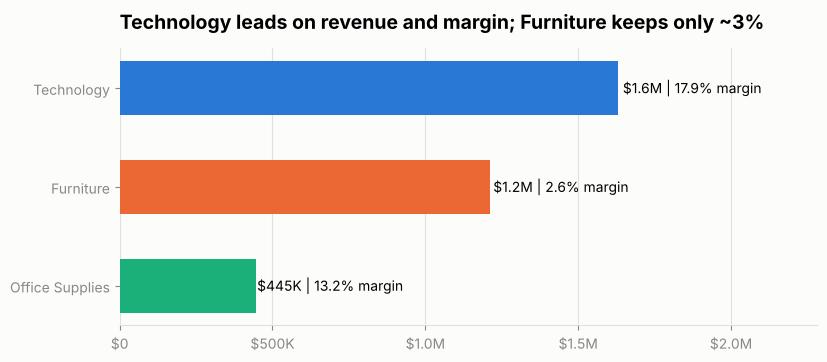

In [6]:
cat = df.groupby("category").agg(sales=("sales","sum"), profit=("profit","sum"))
cat["margin"] = cat.profit / cat.sales
cat = cat.sort_values("sales")
fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.barh(cat.index, cat.sales, color=[CAT[c] for c in cat.index], height=.55)
for b, (c, r) in zip(bars, cat.iterrows()):
    ax.text(b.get_width()*1.01, b.get_y()+b.get_height()/2, f"{money(r.sales)} | {r.margin:.1%} margin", va="center")
ax.set_xlim(0, cat.sales.max()*1.4); ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.grid(axis="y", visible=False); ax.set_title("Technology leads on revenue and margin; Furniture keeps only ~3%")
plt.show()

**Insight:** Technology is both the biggest and the most profitable. Furniture sells a lot but earns very little.

### 3.3 Region x category (heatmap, diverging colors)
**Question:** where exactly is profit weak?

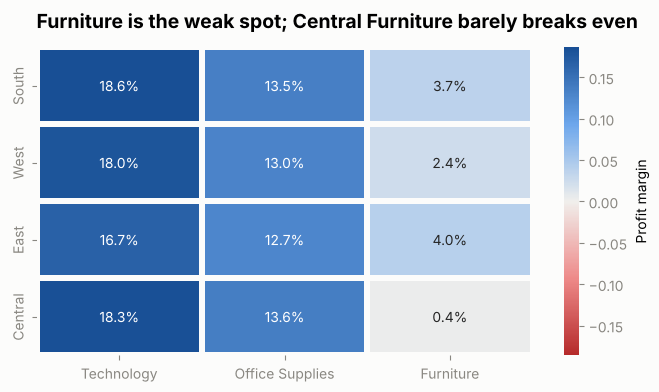

In [7]:
rc = df.groupby(["region","category"]).agg(s=("sales","sum"), p=("profit","sum"))
heat = (rc.p / rc.s).unstack()
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index, ["Technology","Office Supplies","Furniture"]]
lim = abs(heat.values).max()
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(heat, annot=heat.map(lambda v: f"{v:.1%}"), fmt="", cmap=DIV, center=0, vmin=-lim, vmax=lim,
            linewidths=3, linecolor=SURFACE, cbar_kws={"label": "Profit margin"}, ax=ax)
ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
ax.set_title("Furniture is the weak spot; Central Furniture barely breaks even")
plt.show()

**Insight:** Technology and Office Supplies are healthy everywhere. Furniture is the problem, worst in Central (0.4%).

### 3.4 Finding the cause (discount vs margin)
**Question:** *why* is Furniture weak?

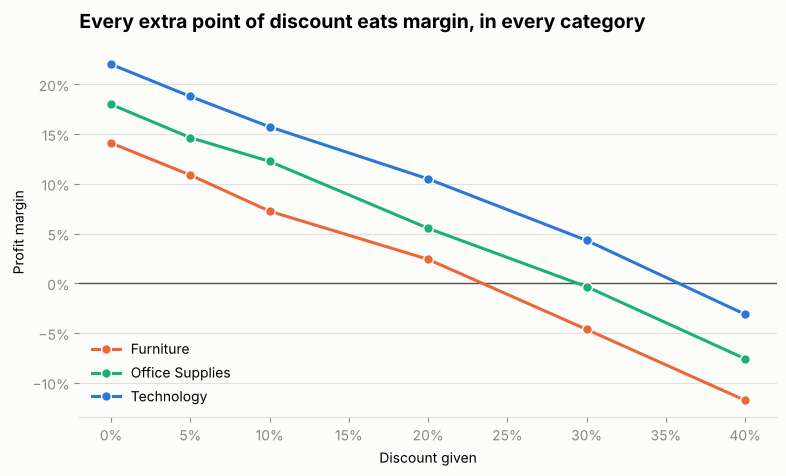

In [8]:
dm = df.groupby(["category","discount"]).apply(lambda g: g.profit.sum()/g.sales.sum(), include_groups=False).rename("margin").reset_index()
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.axhline(0, color=INK2, lw=1)
for c, g in dm.groupby("category"):
    ax.plot(g.discount, g.margin, color=CAT[c], lw=2.2, marker="o", ms=7, markeredgecolor=SURFACE, label=c)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Discount given"); ax.set_ylabel("Profit margin"); ax.grid(axis="x", visible=False); ax.legend(loc="lower left")
ax.set_title("Every extra point of discount eats margin, in every category")
plt.show()

**Insight:** this is the root cause. Margin falls in a straight line as discounts rise, and Furniture turns loss-making beyond roughly 25%.

In [9]:
hi, lo = df[df.discount >= .3], df[df.discount <= .1]
print(f"Margin at discount >= 30%: {hi.profit.sum()/hi.sales.sum():.1%}")
print(f"Margin at discount <= 10%: {lo.profit.sum()/lo.sales.sum():.1%}")
print(f"Share of orders with >= 30% discount: {len(hi)/len(df):.1%}")
print(f"Loss-making orders: {(df.profit < 0).mean():.1%}")

Margin at discount >= 30%: -4.4%
Margin at discount <= 10%: 17.3%
Share of orders with >= 30% discount: 20.2%
Loss-making orders: 18.0%


### 3.5 Distribution (histogram)
**Question:** what does a typical order look like?

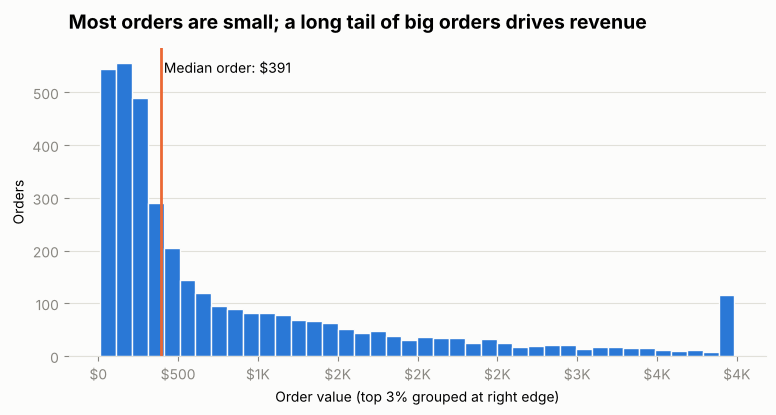

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df.sales.clip(upper=df.sales.quantile(.97)), bins=40, color=BLUE, edgecolor=SURFACE)
ax.axvline(df.sales.median(), color=ORANGE, lw=2)
ax.text(df.sales.median()*1.05, ax.get_ylim()[1]*.92, f"Median order: {money(df.sales.median())}")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money)); ax.grid(axis="x", visible=False)
ax.set_xlabel("Order value (top 3% grouped at right edge)"); ax.set_ylabel("Orders")
ax.set_title("Most orders are small; a long tail of big orders drives revenue")
plt.show()

### 3.6 Seasonality (heatmap, sequential color)

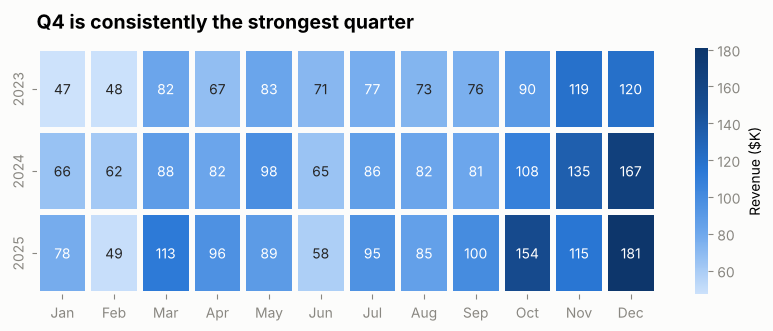

Q4 share of revenue: 36.2%


In [11]:
piv = df.pivot_table(index="year", columns="month", values="sales", aggfunc="sum")
fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(piv/1e3, cmap=SEQ, annot=True, fmt=".0f", linewidths=3, linecolor=SURFACE, cbar_kws={"label": "Revenue ($K)"}, ax=ax)
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], rotation=0)
ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
ax.set_title("Q4 is consistently the strongest quarter")
plt.show()
print(f"Q4 share of revenue: {df[df.month >= 10].sales.sum()/total_sales:.1%}")

### 3.7 Regions side by side (small multiples)

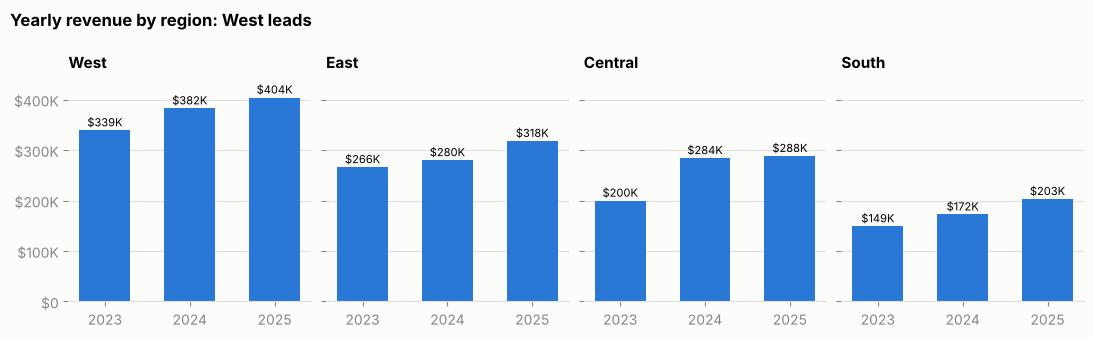

In [12]:
reg_year = df.groupby(["region","year"]).sales.sum().unstack()
order = reg_year.sum(axis=1).sort_values(ascending=False).index
fig, axes = plt.subplots(1, 4, figsize=(11, 3.4), sharey=True)
for ax, r in zip(axes, order):
    v = reg_year.loc[r]
    ax.bar(v.index.astype(str), v.values, color=BLUE, width=.6)
    for x, y in zip(v.index.astype(str), v.values):
        ax.text(x, y + reg_year.values.max()*.02, money(y), ha="center", fontsize=8)
    ax.set_title(r, fontsize=11); ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
fig.suptitle(f"Yearly revenue by region: {order[0]} leads", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 4. Dashboard
For the full one-page dashboard, run `python src/visualize.py` and open `visuals/08_dashboard.png`. A Tableau version can be built with `TABLEAU_GUIDE.md`.

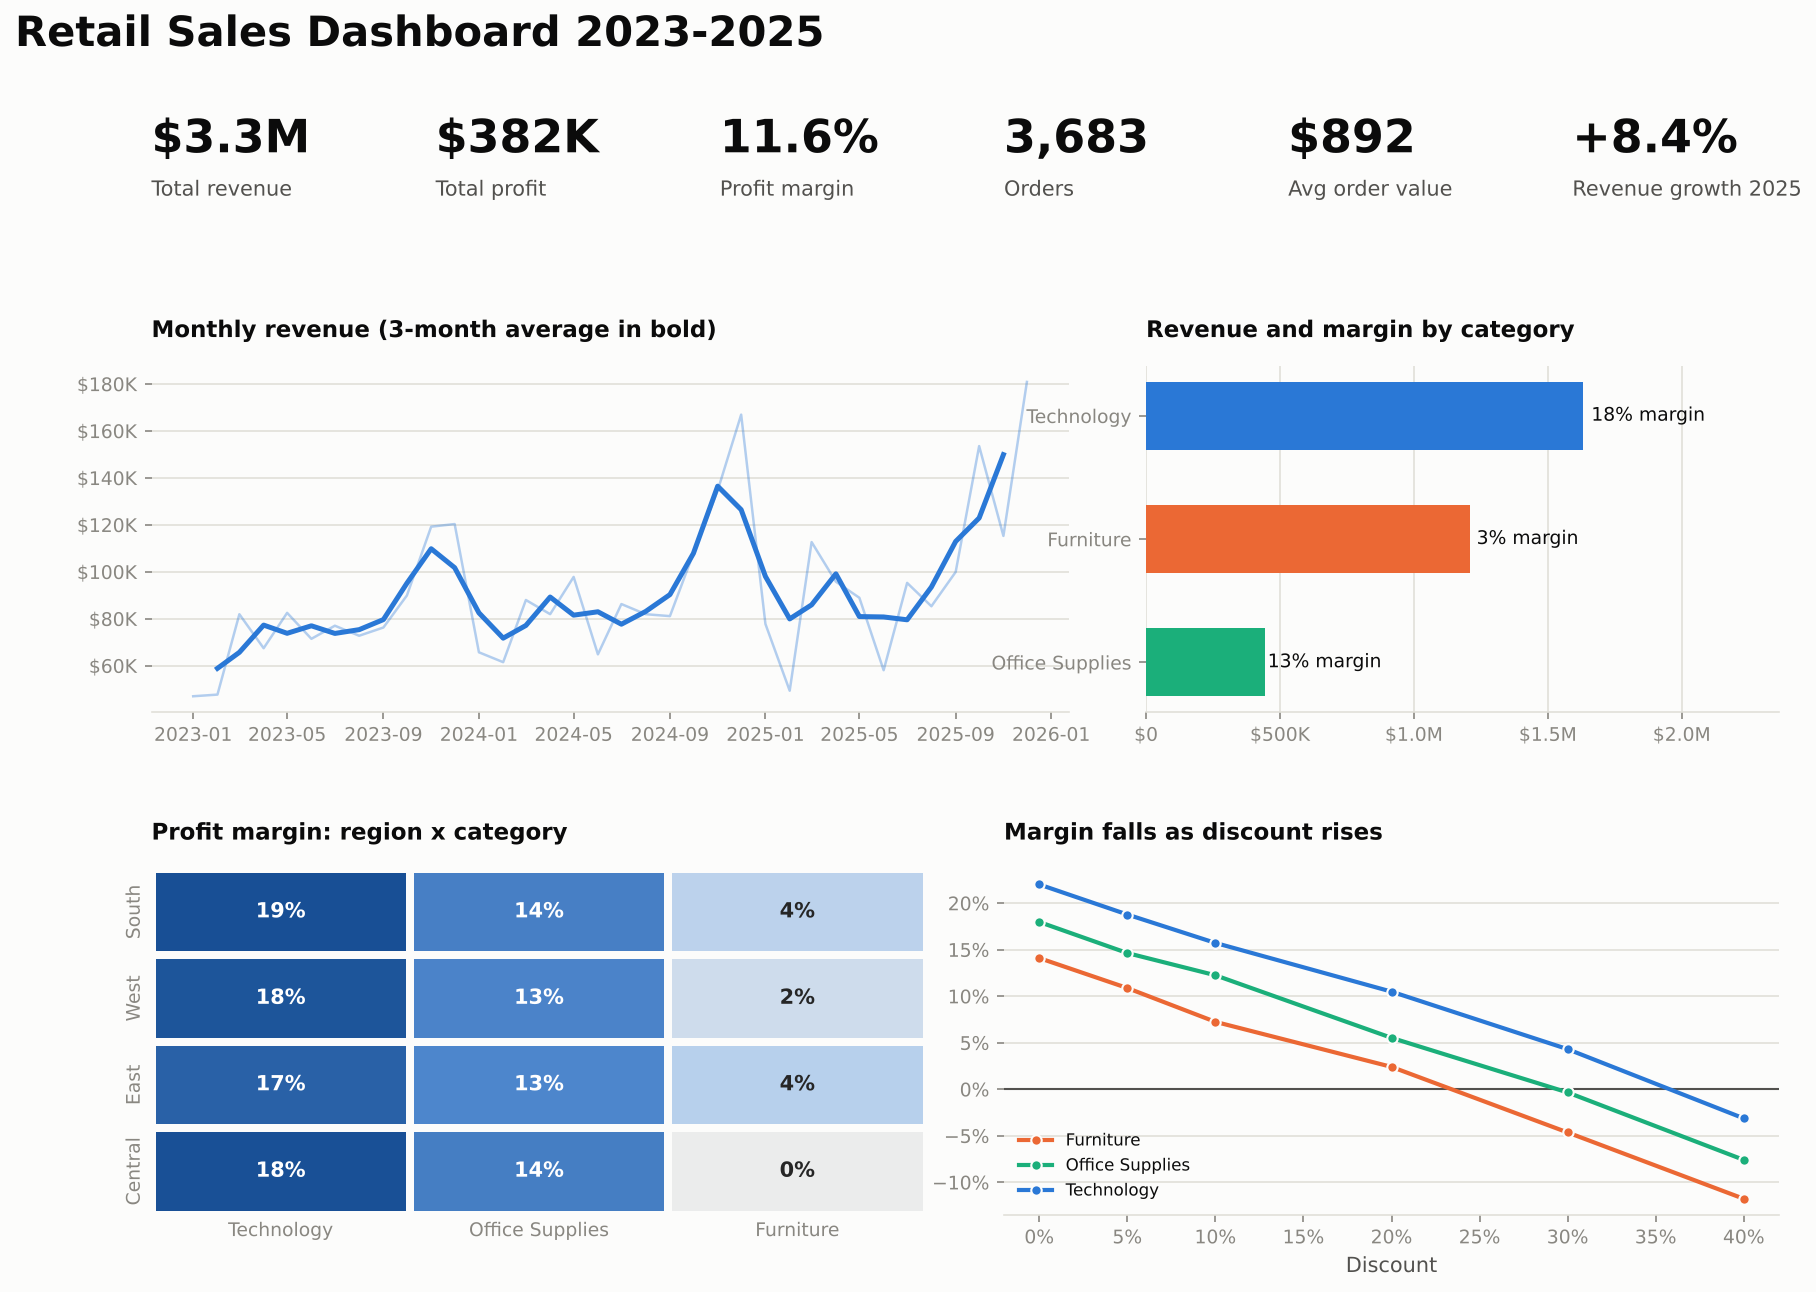

In [13]:
from IPython.display import Image
Image("../visuals/08_dashboard.png")

## 5. The data story and recommendations

**Situation:** revenue is growing about 8% a year with a strong Q4.

**Complication:** profit is not keeping pace. Orders with 30%+ discounts lose money (-4.4% margin vs 17.3% at 10% or less), they make up about 20% of orders, and 18% of all orders are loss-making. Furniture and especially Central Furniture are the weak spots.

**Resolution (decisions):**
1. Cap Furniture discounts at about 20% and require approval above that.
2. Review Central Furniture pricing first.
3. Plan inventory and staffing for Q4, which brings in over a third of revenue.
4. Protect Technology margins; it grows well without deep discounts.

**Next steps:** test the discount cap in one region for a quarter and compare margins; rebuild the dashboard in Tableau for stakeholders.